# 用 1/4 波片产生圆偏振光和椭圆偏振光

**原始数据**：检偏器从 0° 转到 360°（每 10° 一测），记录透射光功率 $A$。共三组：

- **初始态**：未调整波片时的状态（μW）
- **45°**：1/4 波片光轴与起偏方向成 45°（原始记录为 0.448…，已 ×1000 换算为 μW）
- **20°**：1/4 波片转角 20°（原始记录为 0.181… mW，已 ×1000 换算为 μW）

**原理**：1/4 波片使 o 光与 e 光产生 $\pi/2$ 的相位差。若入射线偏振光的振动方向与波片光轴夹角为 45°，出射为圆偏振光；为其他角度时出射为椭圆偏振光。以检偏器转角 $\varphi$ 为极角、透射光强 $A$ 为极径作图：

| 偏振态 | 极坐标图形 |
|---|---|
| 线偏振 | 过原点的双瓣形（两个消光点） |
| 圆偏振 | 圆心在原点的圆（各方向光强相同） |
| 椭圆偏振 | 不经过原点的椭圆 |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.font_manager as fm

# ---------- 字体：英文用 Times New Roman，中文逐字回退到宋体 ----------
_installed = {f.name for f in fm.fontManager.ttflist}
_cjk_candidates = ['SimSun', 'STSong', 'Songti SC', 'Noto Serif SC',
                   'Source Han Serif SC', 'SimHei', 'Microsoft YaHei']
CJK_FONT = next((f for f in _cjk_candidates if f in _installed), 'DejaVu Sans')

# 注意：字体名必须直接写进 font.family 列表，matplotlib 才会逐字回退
rcParams['font.family']        = ['Times New Roman', CJK_FONT, 'DejaVu Sans']
rcParams['mathtext.fontset']   = 'stix'
rcParams['axes.unicode_minus'] = False
rcParams['figure.facecolor']   = 'white'
rcParams['savefig.facecolor']  = 'white'

pd.set_option('display.unicode.east_asian_width', True)

# ---------- 原始数据（均为实测值，未做平滑或对称化） ----------
phi_deg = np.arange(0, 361, 10, dtype=float)          # 检偏器转角 φ / (°)

A_init = np.array([  0.1,   8.4,  30.5,  76.4, 128.0, 185.1,   # 初始态 A / μW
                   244.3, 288.1, 310.4, 324.1, 310.2, 286.3,
                   245.5, 190.0, 133.2,  87.2,  38.2,  10.6,
                     0.0,   9.2,  37.4,  81.6, 128.3, 188.1,
                   241.1, 285.2, 313.3, 328.3, 313.1, 285.2,
                   240.0, 186.2, 130.0,  84.3,  41.2,  11.6,
                     0.0])

A_45 = np.array([448, 457, 450, 465, 465, 460,          # 45° 时 A / μW
                 478, 480, 487, 493, 499, 496,
                 480, 477, 490, 472, 462, 467,
                 478, 477, 480, 484, 493, 498,
                 519, 502, 500, 508, 488, 477,
                 476, 462, 460, 461, 456, 459,
                 461], dtype=float)

A_20 = np.array([0.181, 0.122, 0.106, 0.130, 0.200, 0.288,   # 20° 时 A / μW
                 0.403, 0.523, 0.647, 0.758, 0.832, 0.859,
                 0.856, 0.785, 0.644, 0.530, 0.418, 0.287,
                 0.189, 0.130, 0.114, 0.144, 0.209, 0.301,
                 0.420, 0.554, 0.650, 0.745, 0.785, 0.802,
                 0.783, 0.698, 0.609, 0.502, 0.384, 0.270,
                 0.183]) * 1000

df = pd.DataFrame({
    '检偏器转角 φ/(°)': phi_deg.astype(int),
    '初始态 A/(μW)':    A_init,
    '45° 时 A/(μW)':    A_45,
    '20° 时 A/(μW)':    A_20,
})
display(df.round(1))

print(f'初始态 : 最大 {A_init.max():.1f} μW @ {int(phi_deg[A_init.argmax()])}°，'
      f'最小 {A_init.min():.1f} μW')
print(f'45°    : {A_45.min():.0f}–{A_45.max():.0f} μW，均值 {A_45.mean():.1f} μW，'
      f'起伏 {(A_45.max()-A_45.min())/A_45.mean()*100:.1f}%')
print(f'20°    : 最大 {A_20.max():.1f} μW @ {int(phi_deg[A_20.argmax()])}°，'
      f'最小 {A_20.min():.1f} μW @ {int(phi_deg[A_20.argmin()])}°')


def polar_figure(phi_deg, A, r_max, r_step, legend_label, fname, unit='μW'):
    """Origin 版式极坐标图：左侧径向刻度尺、每 10° 一条辐线。"""
    r_ticks = np.arange(r_step, r_max, r_step)

    fig = plt.figure(figsize=(9.0, 7.2))
    ax = fig.add_axes([0.36, 0.08, 0.592, 0.74], projection='polar')

    ax.plot(np.deg2rad(phi_deg), A, color='black', linewidth=1.0,
            marker='s', markersize=5.5, markerfacecolor='black',
            markeredgecolor='black', label=legend_label, zorder=3)

    ax.set_ylim(0, r_max)
    ax.set_thetagrids(np.arange(0, 360, 10),
                      labels=[f'{d}°' for d in np.arange(0, 360, 10)],
                      fontsize=9.5)
    ax.set_rgrids(r_ticks, labels=[''] * len(r_ticks))   # 只画网格圆，标签另画
    ax.grid(color='#BDBDBD', linewidth=0.6)
    ax.tick_params(axis='x', pad=4)
    ax.spines['polar'].set_linewidth(1.0)

    leg = ax.legend(loc='lower left', bbox_to_anchor=(0.70, 1.02),
                    fontsize=10, frameon=True, borderpad=0.5, handlelength=2.0)
    leg.get_frame().set_linewidth(0.9)
    leg.get_frame().set_edgecolor('black')

    # 左侧径向刻度尺（以圆心为 0，上下对称）
    axr = fig.add_axes([0.13, 0.08, 0.06, 0.74], frameon=False)
    axr.set_xlim(0, 1)
    axr.set_ylim(-r_max, r_max)
    axr.set_xticks([])
    axr.set_yticks([])
    axr.plot([1, 1], [-r_max, r_max], color='black', linewidth=0.9, clip_on=False)
    for v in r_ticks:
        for s in (1, -1):
            axr.plot([1, 0.80], [s * v, s * v], color='black',
                     linewidth=0.8, clip_on=False)
            axr.text(0.74, s * v, f'{v:g}', ha='right', va='center', fontsize=9)
    axr.plot([1, 0.80], [0, 0], color='black', linewidth=0.8, clip_on=False)
    axr.text(0.74, 0, '0', ha='right', va='center', fontsize=9)
    axr.text(-1.30, 0, f'A ({unit})', rotation=90, ha='center', va='center',
             fontsize=13)

    plt.savefig(fname, dpi=300, bbox_inches='tight')
    plt.show()


def linear_fit_figure(phi_deg, A, y_lim, y_ticks, title, legend_label, fname,
                      table_bbox=(0.08, 0.64, 0.50, 0.28)):
    """A–φ 散点 + 直线拟合（Origin 版式），含拟合结果框。"""
    n = len(phi_deg)
    b, a = np.polyfit(phi_deg, A, 1)          # 拟合 A = a + b·φ
    y_hat = a + b * phi_deg
    ss_res = np.sum((A - y_hat) ** 2)
    ss_tot = np.sum((A - A.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - 2)

    sxx = np.sum((phi_deg - phi_deg.mean()) ** 2)
    s = np.sqrt(ss_res / (n - 2))
    se_b = s / np.sqrt(sxx)
    se_a = s * np.sqrt(1 / n + phi_deg.mean() ** 2 / sxx)

    print(f'{legend_label}: A = {a:.2f} + {b:.4f}·φ，R² = {r2:.4f}，Adj. R² = {adj_r2:.4f}')

    fig, ax = plt.subplots(figsize=(7.4, 5.4))
    ax.plot(phi_deg, A, linestyle='none', marker='s', markersize=5.5,
            color='black', label=legend_label, zorder=3)

    xx = np.linspace(0, 360, 200)
    ax.plot(xx, a + b * xx, color='#C00000', linewidth=1.3,
            label='Linear Fit', zorder=2)

    ax.set_xlim(0, 360)
    ax.set_ylim(*y_lim)
    ax.set_xticks(np.arange(0, 361, 60))
    ax.set_yticks(y_ticks)
    ax.tick_params(direction='in', length=4.5, width=0.9,
                   top=True, right=True, labelsize=11, pad=6)
    for sp in ax.spines.values():
        sp.set_linewidth(1.0)
    ax.set_xlabel('检偏器转角 φ/(°)', fontsize=14, labelpad=6)
    ax.set_ylabel('功率 A/(μW)', fontsize=14, labelpad=8)
    ax.set_title(title, fontsize=17, x=0.40, pad=42)

    leg = ax.legend(loc='lower left', bbox_to_anchor=(0.58, 1.015),
                    fontsize=10, frameon=True, borderpad=0.5,
                    labelspacing=0.35, handlelength=2.2)
    leg.get_frame().set_linewidth(0.9)
    leg.get_frame().set_edgecolor('black')

    # Origin 风格拟合结果框
    tbl = ax.table(cellText=[['Equation',      'y = a + b·x',   ''],
                             ['Adj. R-Square', f'{adj_r2:.5f}', ''],
                             ['',              'Value',         'Standard Error'],
                             ['Intercept',     f'{a:.2f}',      f'{se_a:.2f}'],
                             ['Slope',         f'{b:.4f}',      f'{se_b:.4f}']],
                   cellLoc='left', colWidths=[0.40, 0.28, 0.32],
                   bbox=table_bbox)
    tbl.auto_set_font_size(False)
    for cell in tbl.get_celld().values():
        cell.set_edgecolor('#808080')
        cell.set_linewidth(0.6)
        cell.set_facecolor('white')
        cell.get_text().set_fontsize(9.5)

    plt.savefig(fname, dpi=300, bbox_inches='tight')
    plt.show()


,检偏器转角 φ/(°),初始态 A/(μW),45° 时 A/(μW),20° 时 A/(μW)
0,0,0.1,448.0,181.0
1,10,8.4,457.0,122.0
2,20,30.5,450.0,106.0
3,30,76.4,465.0,130.0
4,40,128.0,465.0,200.0
5,50,185.1,460.0,288.0
6,60,244.3,478.0,403.0
7,70,288.1,480.0,523.0
8,80,310.4,487.0,647.0
9,90,324.1,493.0,758.0


初始态 : 最大 328.3 μW @ 270°，最小 0.0 μW
45°    : 448–519 μW，均值 477.4 μW，起伏 14.9%
20°    : 最大 859.0 μW @ 110°，最小 106.0 μW @ 20°


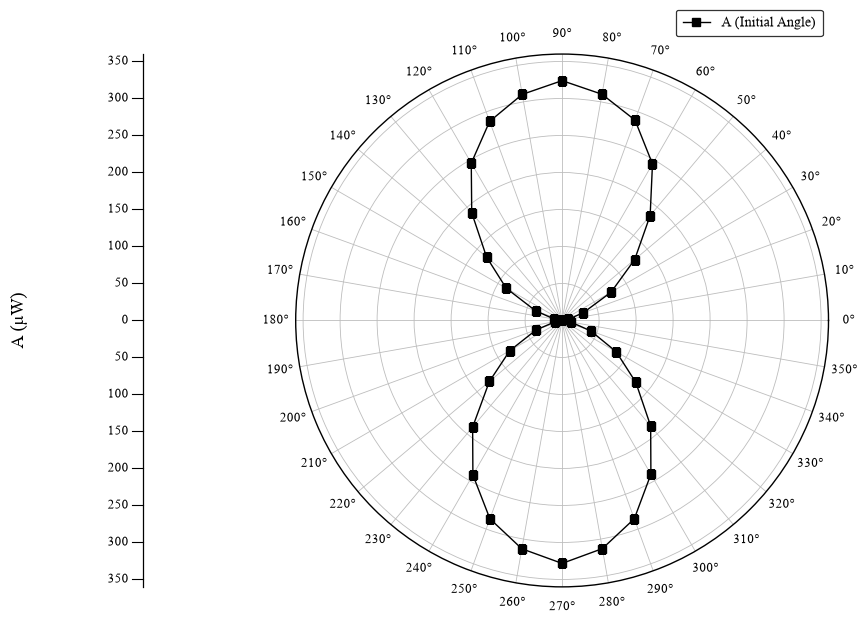

In [2]:
# ---------- 图 1：初始态 ----------
polar_figure(phi_deg, A_init, r_max=360, r_step=50,
             legend_label='A (Initial Angle)',
             fname='图1_四分之一波片_极坐标.png', unit='μW')

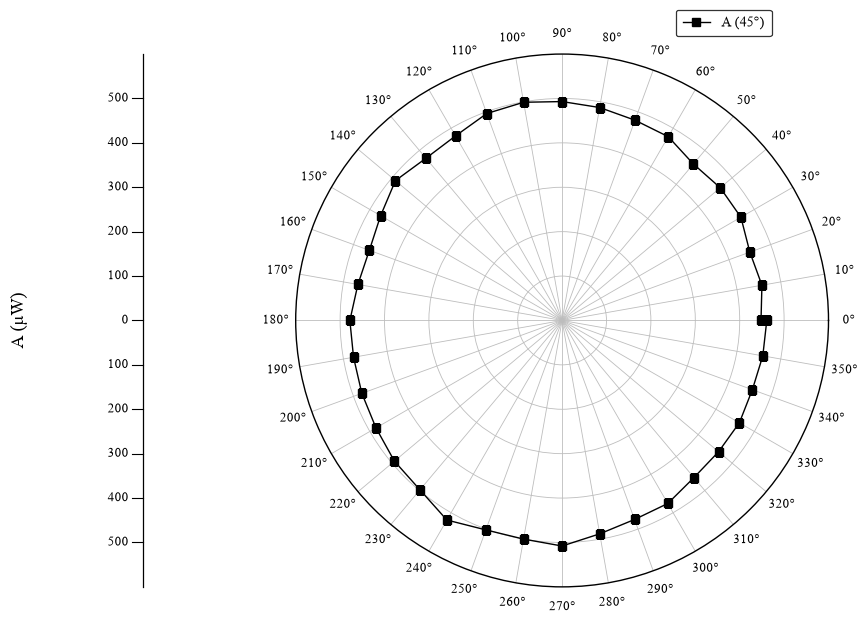

In [3]:
# ---------- 图 2：1/4 波片转角 45° ----------
polar_figure(phi_deg, A_45, r_max=600, r_step=100,
             legend_label='A (45°)',
             fname='图2_四分之一波片_45度_极坐标.png', unit='μW')

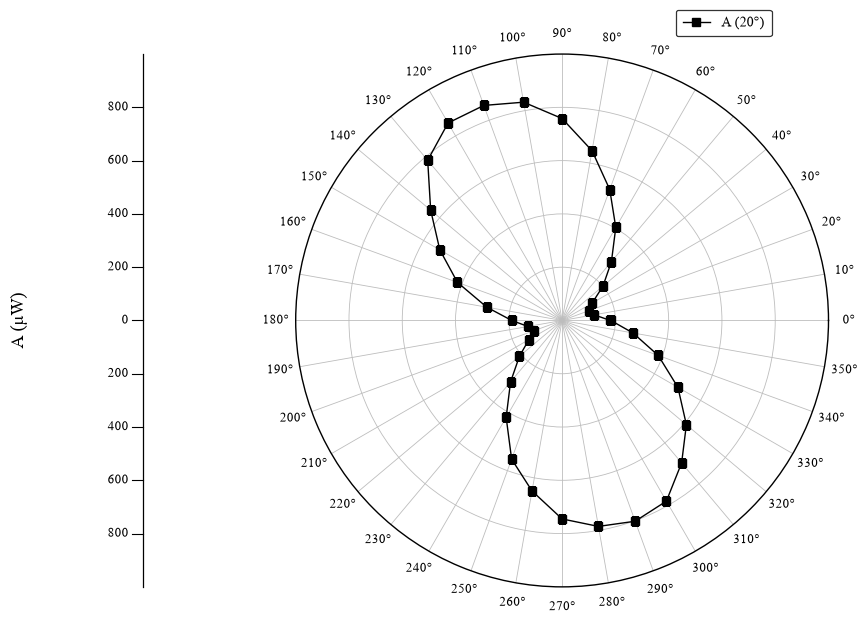

In [4]:
# ---------- 图 3：1/4 波片转角 20° ----------
polar_figure(phi_deg, A_20, r_max=1000, r_step=200,
             legend_label='A (20°)',
             fname='图3_四分之一波片_20度_极坐标.png', unit='μW')

A (Initial Angle): A = 155.46 + 0.0073·φ，R² = 0.0000，Adj. R² = -0.0285


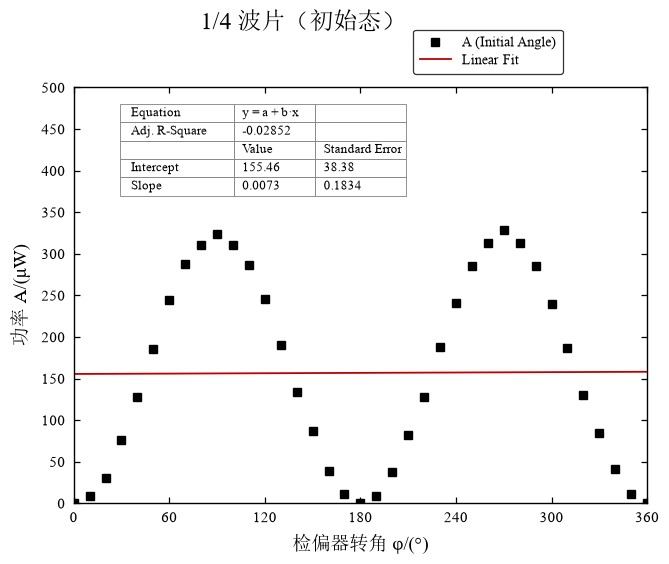

In [5]:
# ---------- 图 4：初始态 A–φ 直线拟合 ----------
linear_fit_figure(phi_deg, A_init, y_lim=(0, 500), y_ticks=np.arange(0, 501, 50),
                  title='1/4 波片（初始态）', legend_label='A (Initial Angle)',
                  fname='图4_初始态_角度-功率_拟合.png',
                  table_bbox=(0.08, 0.74, 0.50, 0.22))

A (45°): A = 473.89 + 0.0197·φ，R² = 0.0151，Adj. R² = -0.0130


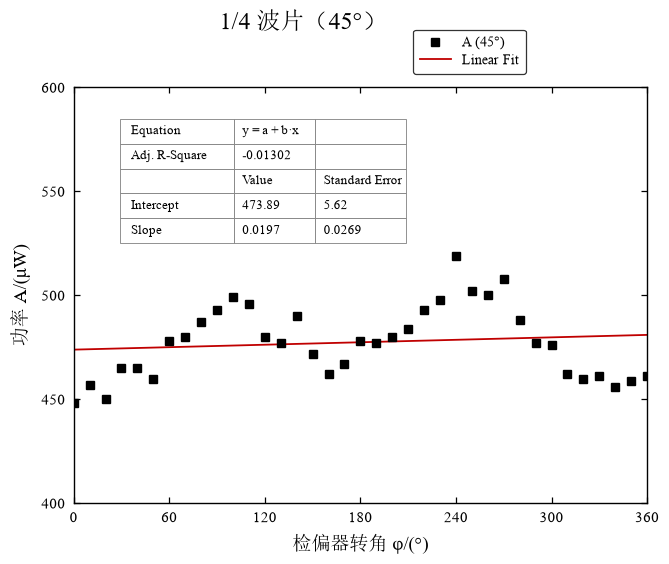

In [6]:
# ---------- 图 5：45° A–φ 直线拟合 ----------
linear_fit_figure(phi_deg, A_45, y_lim=(400, 600), y_ticks=np.arange(400, 601, 50),
                  title='1/4 波片（45°）', legend_label='A (45°)',
                  fname='图5_45度_角度-功率_拟合.png',
                  table_bbox=(0.08, 0.625, 0.50, 0.30))

## 结果分析

- **初始态**：$A(\varphi)$ 为过原点的双瓣形，$\varphi=0^\circ$、$180^\circ$、$360^\circ$ 处消光，
  说明是线偏振光。90° 与 270° 分别为 324.1 / 328.3 μW；左右最大不对称量约 10.8 μW、
  上下约 10.7 μW——这些偏差**原样保留**，未做对称化处理。
- **45°**：各方向光强基本不变（448–519 μW，均值 477 μW，起伏约 15%），
  极坐标图近似为**圆心在原点的圆**，即得到**圆偏振光**。
- **20°**：图形是**不经过原点的椭圆**——近心端 106 μW（20°），远心端 859 μW（110°），
  两者方向相差 90°，与椭圆偏振光的特征一致。椭圆中心相对圆心的偏移约
  $(106+859)/2\approx483$ μW，说明是**椭圆偏振光**而非圆偏振光。
- 三图对照：波片转角从 0°→20°→45°，图形由双瓣（线偏振）→偏心椭圆（椭圆偏振）→近似圆
  （圆偏振），验证了 1/4 波片的作用。

### A–φ 直角坐标拟合

- 初始态：$A=155.46+0.0073\,\varphi$，$R^2\approx0.000$，Adj. R-Square = -0.0285。
- 45°：$A=473.89+0.0197\,\varphi$，$R^2\approx0.015$，Adj. R-Square = -0.0130。
- 两条拟合线都接近水平。初始态的光强本来按 $\cos^2$ 规律周期变化，直线拟合无法描述全段趋势，
  $R^2\approx0$（Adj. R-Square 为负）属预期，仅作整体趋势参考；
  45° 的斜率仅约 0.02 μW/(°)，与“光强不随角度变化”的圆偏振结论一致。